# 04. Проверка устойчивости и бизнес-выводы

Ноутбук 03 дал итоговую модель: LightGBM, WAPE 22,7% на test (июль–декабрь 2025) против 29,5% у baseline.
Здесь проверяем, можно ли этому верить и что это значит для банка:

1. **Несколько периодов проверки.** Один test мог оказаться удачным. Проверяем модель на четырёх кварталах подряд.
2. **Абляция.** Что даёт каждая группа признаков: убираем по одной и смотрим, насколько вырастает ошибка.
3. **Почему ошибка за неделю меньше дневной** (9,4% против 22,7%).
4. **Какой запас закладывать при загрузке.** Вместо фиксированных 15% подбираем запас под нужную надёжность и считаем, сколько денег это стоит.

Модель, признаки и параметры те же, что в ноутбуке 03 (`models/features.json`). Новые признаки и новые модели не добавляем.

In [1]:
from pathlib import Path
import json, sys
import lightgbm as lgb
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))
from src.forecast import HORIZON, forecast_week, load_model, prepare, valid_starts

FIG = ROOT / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

BLUE, ORANGE, AQUA, GRAY = "#2a78d6", "#eb6834", "#1baf7a", "#a3a29c"
INK, INK2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.figsize": (11, 4.2), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#d6d5d0", "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "legend.frameon": False, "lines.linewidth": 2, "axes.axisbelow": True,
})
pct0 = mticker.PercentFormatter(1.0, decimals=0)
fmt_int = lambda v: f"{v:,.0f}".replace(",", " ")
fmt_pct = lambda v: f"{v:.1%}"

def save(fig, name):
    fig.savefig(FIG / f"{name}.png", bbox_inches="tight")

SEED = 42
TARGET = "cash_out"
TEST_START, TEST_END = pd.Timestamp("2025-07-01"), pd.Timestamp("2025-12-31")
meta = json.loads((ROOT / "models" / "features.json").read_text())
PARAMS, N_TREES, FEATURES = meta["params"], meta["n_estimators"], meta["features"]

df = pd.read_parquet(ROOT / "data" / "processed" / "daily.parquet")
df = df.sort_values(["atm_id", "date"]).reset_index(drop=True)
print(df.shape, df.date.min().date(), "…", df.date.max().date())
print(f"Модель из 03: {len(FEATURES)} признаков, {N_TREES} деревьев")

(82565, 39) 2024-01-01 … 2025-12-31
Модель из 03: 22 признаков, 897 деревьев


Признаки строим так же, как в ноутбуке 03 (раздел 2): дни сбоев не используются как история.

In [2]:
g = df.groupby("atm_id", sort=False)
clean_cash = df.cash_out.where(~df.is_disrupted)
cg = clean_cash.groupby(df["atm_id"], sort=False)
for k in (1, 7, 14, 28):
    df[f"lag_{k}"] = cg.shift(k)
df["roll_mean_7"] = cg.transform(lambda s: s.shift(1).rolling(7, min_periods=3).mean())
df["roll_mean_28"] = cg.transform(lambda s: s.shift(1).rolling(28, min_periods=10).mean())
df["naive_lag7_raw"] = g["cash_out"].shift(7)
df["dow_mean_4w"] = pd.concat([cg.shift(k) for k in (7, 14, 21, 28)], axis=1).mean(axis=1)
for c in ["temp_avg", "precip_mm", "snowfall_mm", "wind_max"]:
    df[f"{c}_lag1"] = g[c].shift(1)
df["fx_shock_last3"] = g["fx_shock"].transform(
    lambda s: s.astype(int).shift(1).rolling(3, min_periods=1).max()).fillna(0).astype(int)
df["is_street"] = (df["placement"] == "street").astype(int)
df["dom"] = df.date.dt.day

CAT = ["atm_type", "district_id"]
for c in ["is_holiday", "is_pre_holiday", "is_payday", "is_pension_day", "is_ramadan", "is_weekend", "is_street", "fx_shock_last3"]:
    df[c] = df[c].astype(int)
CATEGORIES = {c: sorted(df[c].unique()) for c in CAT}
has_history = df["naive_lag7_raw"].notna() & df["dow_mean_4w"].notna() & df["roll_mean_28"].notna()
usable = has_history & ~df.is_disrupted

def lgb_frame(d, feats):
    x = d[feats].copy()
    for c in CAT:
        if c in feats:
            x[c] = pd.Categorical(x[c], categories=CATEGORIES[c])
    return x

def wape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return np.abs(y - p).sum() / y.sum()

def fit(train, feats, seed=SEED):
    m = lgb.LGBMRegressor(n_estimators=N_TREES, random_state=seed, verbose=-1, **PARAMS)
    m.fit(lgb_frame(train, feats), train[TARGET])
    return m

## 1. Проверка на нескольких периодах (rolling-origin backtest)

В ноутбуках 02 и 03 модель проверялась на одном периоде: июль–декабрь 2025. Вдруг он просто удачный?

Повторяем проверку четыре раза. Для каждого квартала 2025 года модель учится **только на данных до начала квартала** и прогнозирует весь квартал на день вперёд. Так работала бы модель в банке, если бы её переобучали раз в квартал.

Параметры и число деревьев те же, что у итоговой модели. Оговорка: параметры подбирались Optuna на мае–июне 2025, поэтому для Q1 и Q2 проверка чуть оптимистичнее. Для Q3 и Q4 она полностью честная.

In [3]:
folds = {
    "Q1 2025 (янв–мар)": ("2025-01-01", "2025-03-31"),
    "Q2 2025 (апр–июн)": ("2025-04-01", "2025-06-30"),
    "Q3 2025 (июл–сен)": ("2025-07-01", "2025-09-30"),
    "Q4 2025 (окт–дек)": ("2025-10-01", "2025-12-31"),
}
rows = []
for name, (a, b) in folds.items():
    a, b = pd.Timestamp(a), pd.Timestamp(b)
    tr = df[usable & (df.date < a)]
    te = df[usable & df.date.between(a, b)]
    p = fit(tr, FEATURES).predict(lgb_frame(te, FEATURES))
    y = te[TARGET]
    rows.append({"период": name, "train, мес.": round((a - tr.date.min()).days / 30.4),
                 "строк test": len(te),
                 "Naive (7 дней назад)": wape(y, te.naive_lag7_raw),
                 "Baseline (ср. по дню недели)": wape(y, te.dow_mean_4w),
                 "LightGBM": wape(y, p)})
bt = pd.DataFrame(rows).set_index("период")
bt["лучше baseline"] = 1 - bt["LightGBM"] / bt["Baseline (ср. по дню недели)"]
print("WAPE, прогноз на следующий день, дни без сбоев:")
print(bt.to_string(formatters={c: fmt_pct for c in ["Naive (7 дней назад)", "Baseline (ср. по дню недели)", "LightGBM", "лучше baseline"]}))
print(f"\nВ среднем по 4 кварталам: LightGBM {bt.LightGBM.mean():.1%}, baseline {bt['Baseline (ср. по дню недели)'].mean():.1%}; "
      f"модель лучше на {bt['лучше baseline'].min():.0%}–{bt['лучше baseline'].max():.0%} в каждом квартале")

WAPE, прогноз на следующий день, дни без сбоев:
                   train, мес.  строк test Naive (7 дней назад) Baseline (ср. по дню недели) LightGBM лучше baseline
период                                                                                                              
Q1 2025 (янв–мар)           12       10274                44.1%                        32.5%    25.0%          23.3%
Q2 2025 (апр–июн)           15       10611                40.8%                        31.5%    23.6%          25.2%
Q3 2025 (июл–сен)           18       10836                38.1%                        29.0%    22.6%          22.2%
Q4 2025 (окт–дек)           21       10890                38.5%                        30.0%    22.8%          24.0%

В среднем по 4 кварталам: LightGBM 23.5%, baseline 30.8%; модель лучше на 22%–25% в каждом квартале


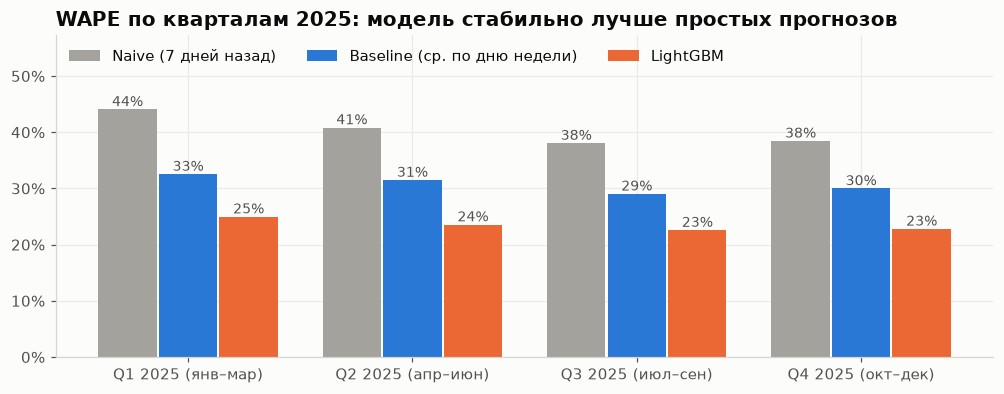

In [4]:
fig, ax = plt.subplots(figsize=(11, 3.8))
x = np.arange(len(bt))
for i, (col, c) in enumerate([("Naive (7 дней назад)", GRAY), ("Baseline (ср. по дню недели)", BLUE), ("LightGBM", ORANGE)]):
    ax.bar(x + (i - 1) * 0.27, bt[col], width=0.26, color=c, label=col)
    for xi, v in zip(x, bt[col]):
        ax.text(xi + (i - 1) * 0.27, v, f"{v:.0%}", ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_xticks(x, bt.index)
ax.yaxis.set_major_formatter(pct0)
ax.set_title("WAPE по кварталам 2025: модель стабильно лучше простых прогнозов")
ax.legend(loc="upper left", ncols=3)
ax.set_ylim(0, bt["Naive (7 дней назад)"].max() * 1.3)
save(fig, "19_backtest_quarters"); plt.show()

## 2. Абляция: что даёт каждая группа признаков

Учим модель на том же train (до 30.06.2025) и проверяем на том же test (июль–декабрь 2025), но каждый раз **без одной группы признаков**. Насколько выросла ошибка — столько эта группа и даёт.

Чтобы не принять случайность за эффект, каждый вариант учим с 3 разными seed и берём среднее.

In [5]:
groups = {
    "история выдачи (лаги, средние)": ["lag_1", "lag_7", "lag_14", "lag_28", "roll_mean_7", "roll_mean_28"],
    "календарь (день недели и месяца, праздники, пенсии, зарплата)":
        ["dow", "dom", "is_holiday", "is_pre_holiday", "is_payday", "is_pension_day", "is_ramadan", "is_weekend"],
    "место (тип банкомата, район, улица)": ["atm_type", "district_id", "is_street"],
    "погода": ["temp_avg_lag1", "precip_mm_lag1", "snowfall_mm_lag1", "wind_max_lag1"],
    "скачки курса": ["fx_shock_last3"],
}
assert sorted(sum(groups.values(), [])) == sorted(FEATURES), "группы должны покрывать все признаки"

train = df[usable & (df.date < TEST_START)]
test = df[usable & df.date.between(TEST_START, TEST_END)]
y = test[TARGET]
SEEDS = (1, 2, 3)

def score(feats):
    return np.mean([wape(y, fit(train, feats, s).predict(lgb_frame(test, feats))) for s in SEEDS])

full = score(FEATURES)
abl = []
for name, cols in groups.items():
    w = score([f for f in FEATURES if f not in cols])
    abl.append({"убрали": name, "признаков": len(cols), "WAPE без группы": w, "рост ошибки, п.п.": (w - full) * 100})
abl = pd.DataFrame(abl).set_index("убрали").sort_values("рост ошибки, п.п.", ascending=False)
only_hist = score(groups["история выдачи (лаги, средние)"] + ["dow"])
print(f"Полная модель: WAPE {full:.2%} (среднее по seed {SEEDS})")
print(abl.to_string(formatters={"WAPE без группы": "{:.2%}".format, "рост ошибки, п.п.": "{:+.2f}".format}))
print(f"\nДля сравнения: только история + день недели — WAPE {only_hist:.2%}; "
      f"baseline (среднее по дню недели) — {wape(y, test.dow_mean_4w):.2%}")

Полная модель: WAPE 22.75% (среднее по seed (1, 2, 3))
                                                               признаков WAPE без группы рост ошибки, п.п.
убрали                                                                                                    
история выдачи (лаги, средние)                                         6          30.19%             +7.43
календарь (день недели и месяца, праздники, пенсии, зарплата)          8          28.29%             +5.53
место (тип банкомата, район, улица)                                    3          24.12%             +1.37
скачки курса                                                           1          22.76%             +0.01
погода                                                                 4          22.63%             -0.13

Для сравнения: только история + день недели — WAPE 27.44%; baseline (среднее по дню недели) — 29.50%


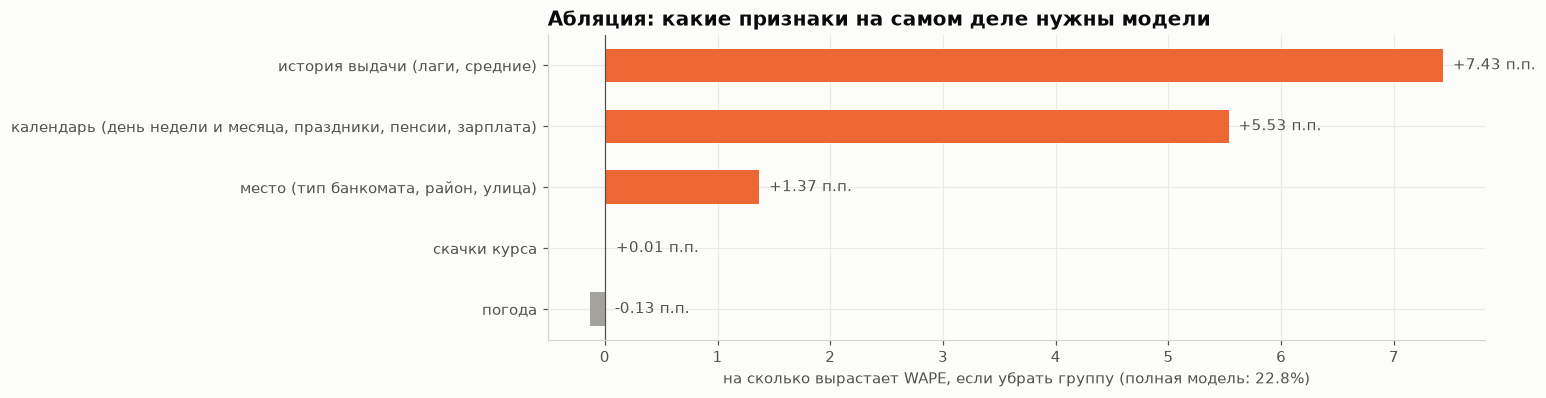

In [6]:
fig, ax = plt.subplots(figsize=(11, 3.6))
a = abl.iloc[::-1]
ax.barh(a.index, a["рост ошибки, п.п."], color=[ORANGE if v > 1 else BLUE if v > 0.1 else GRAY for v in a["рост ошибки, п.п."]], height=0.55)
for yv, v in enumerate(a["рост ошибки, п.п."]):
    ax.text(max(v, 0), yv, f"  {v:+.2f} п.п.", va="center", fontsize=10, color=INK2)
ax.axvline(0, color=INK2, linewidth=0.8)
ax.set_xlabel(f"на сколько вырастает WAPE, если убрать группу (полная модель: {full:.1%})")
ax.set_title("Абляция: какие признаки на самом деле нужны модели")
save(fig, "20_ablation"); plt.show()

## 3. Почему ошибка за неделю намного меньше дневной

Дальше работаем с недельным прогнозом, как в демо (`src/forecast.py`): прогноз на 7 дней строится по шагам, каждый следующий день опирается на прогноз предыдущего. Будущих фактов модель не видит. Берём все недели в test, где не было сбоев.

In [7]:
model, meta_ = load_model()
dfp = prepare(pd.read_parquet(ROOT / "data" / "processed" / "daily.parquet"))
starts = valid_starts(dfp, TEST_START, TEST_END - pd.Timedelta(days=HORIZON - 1))
res = forecast_week(dfp, starts, model, meta_)
clean = ~res["disrupted"].any(1)
act, pm, pb = res["actual"][clean], res["model"][clean], res["baseline"][clean]
dates = dfp["date"].to_numpy()[starts][clean]
print(f"Недель (банкомат × день начала) без сбоев: {clean.sum():,}".replace(",", " "))

err = pm - act                      # ошибка по дням, сом
wape_day = np.abs(err).sum() / act.sum()
wape_week = np.abs(err.sum(1)).sum() / act.sum()
cancel = 1 - np.abs(err.sum(1)).sum() / np.abs(err).sum()

# Корреляция ошибок разных дней одной недели (в долях от уровня банкомата)
rel = err / act.mean(1, keepdims=True)
c = np.corrcoef(rel.T)
mean_corr = c[np.triu_indices(HORIZON, 1)].mean()
# Если бы ошибки дней были независимы, недельная относительная ошибка была бы примерно в √7 раз меньше
indep = wape_day / np.sqrt(HORIZON)

print(f"Средняя ошибка одного дня (WAPE, недельный прогноз): {wape_day:.1%}")
print(f"Ошибка суммы за неделю (WAPE):                     {wape_week:.1%}")
print(f"Часть дневных ошибок, которая гасит друг друга:    {cancel:.0%}")
print(f"Средняя корреляция ошибок двух дней одной недели:  {mean_corr:+.2f}")
print(f"Если бы ошибки были независимы, неделя дала бы ≈   {indep:.1%}")
print(f"Смещение за неделю (прогноз − факт) / факт:        {err.sum() / act.sum():+.1%}")

Недель (банкомат × день начала) без сбоев: 19 629
Средняя ошибка одного дня (WAPE, недельный прогноз): 22.7%
Ошибка суммы за неделю (WAPE):                     9.4%
Часть дневных ошибок, которая гасит друг друга:    59%
Средняя корреляция ошибок двух дней одной недели:  +0.02
Если бы ошибки были независимы, неделя дала бы ≈   8.6%
Смещение за неделю (прогноз − факт) / факт:        +0.8%


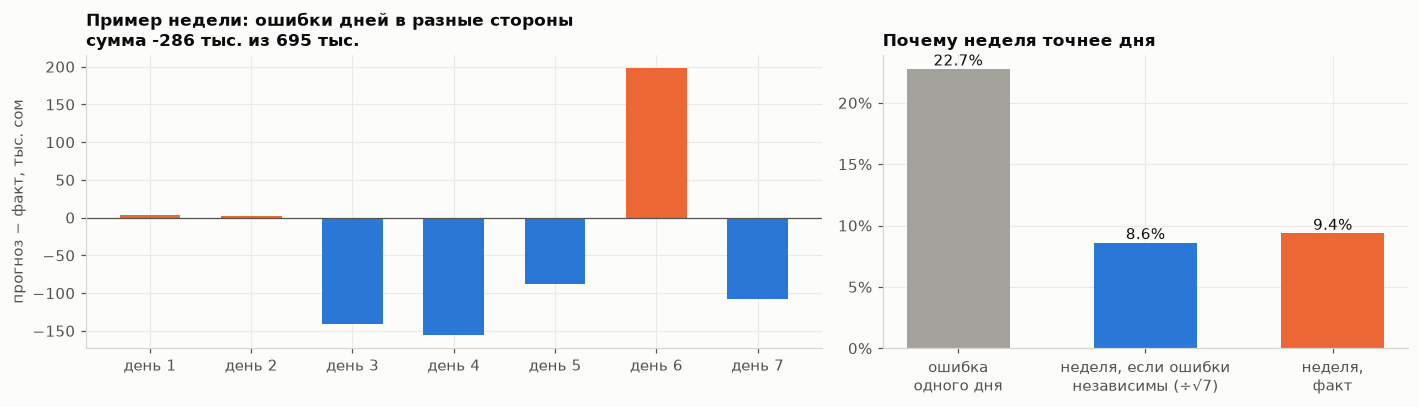

In [8]:
# типичная неделя: недельная ошибка и доля «погашенных» ошибок близки к средним
kept = np.abs(err.sum(1)) / np.abs(err).sum(1)
i = int(np.argmin(np.abs(np.abs(err.sum(1)) / act.sum(1) - wape_week) / wape_week + np.abs(kept - (1 - cancel)) / (1 - cancel)))
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})
ax = axes[0]
days = np.arange(HORIZON)
ax.bar(days, err[i] / 1e3, color=[ORANGE if v > 0 else BLUE for v in err[i]], width=0.6)
ax.axhline(0, color=INK2, linewidth=0.8)
ax.set_xticks(days, [f"день {d + 1}" for d in days])
ax.set_ylabel("прогноз − факт, тыс. сом")
ax.set_title(f"Пример недели: ошибки дней в разные стороны,\nсумма {err[i].sum() / 1e3:+,.0f} тыс. из {np.abs(err[i]).sum() / 1e3:,.0f} тыс.".replace(",", " "), fontsize=11)
ax = axes[1]
vals = [wape_day, indep, wape_week]
ax.bar(["ошибка\nодного дня", "неделя, если ошибки\nнезависимы (÷√7)", "неделя,\nфакт"], vals, color=[GRAY, BLUE, ORANGE], width=0.55)
for xi, v in enumerate(vals):
    ax.text(xi, v, f"{v:.1%}", ha="center", va="bottom", fontsize=10)
ax.yaxis.set_major_formatter(pct0)
ax.set_title("Почему неделя точнее дня", fontsize=11)
fig.tight_layout(); save(fig, "21_week_vs_day"); plt.show()

## 4. Какой запас закладывать при загрузке

В демо загрузка = прогноз на неделю + 15%. Но 15% взяты «на глаз». Правильный вопрос для банка: **какая доля недель должна обходиться без опустошения банкомата, и сколько денег ради этого придётся держать без дела?**

Чтобы не подгонять ответ под test, **запас выбираем на июле–сентябре, а проверяем на октябре–декабре.**

- «Хватило» — загрузки хватило на всю неделю (без учёта промежуточных инкассаций);
- «Без дела» — сколько денег в среднем осталось в банкомате к концу недели.

In [9]:
fact_w = act.sum(1)
sel_part = dates < np.datetime64("2025-10-01")
chk_part = ~sel_part
buffers = np.round(np.arange(0, 1.001, 0.01), 2)

def load_stats(pred_w, fact, b):
    load = pred_w * (1 + b)
    return {"хватило": (load >= fact).mean(), "без дела, сом": np.clip(load - fact, 0, None).mean(),
            "нехватка, сом": np.clip(fact - load, 0, None).mean()}

curves = {m: pd.DataFrame([load_stats(p.sum(1)[sel_part], fact_w[sel_part], b) for b in buffers], index=buffers)
          for m, p in [("модель", pm), ("baseline", pb)]}

TARGETS = (0.90, 0.95, 0.98)
rows = []
for tgt in TARGETS:
    for m, p in [("модель", pm), ("baseline", pb)]:
        cur = curves[m]
        ok = cur.index[cur["хватило"] >= tgt]
        b = float(ok.min()) if len(ok) else np.nan
        chk = load_stats(p.sum(1)[chk_part], fact_w[chk_part], b)
        rows.append({"цель": f"{tgt:.0%} недель", "прогноз": m, "запас (выбран на июл–сен)": b,
                     "хватило на окт–дек": chk["хватило"], "без дела, сом": chk["без дела, сом"]})
buf = pd.DataFrame(rows).set_index(["цель", "прогноз"])
print("Запас выбран на июле–сентябре, проверка на октябре–декабре:")
print(buf.to_string(formatters={"запас (выбран на июл–сен)": "{:.0%}".format, "хватило на окт–дек": "{:.1%}".format,
                                "без дела, сом": fmt_int}))

saving = {t: buf.loc[(f"{t:.0%} недель", "baseline"), "без дела, сом"] - buf.loc[(f"{t:.0%} недель", "модель"), "без дела, сом"]
          for t in TARGETS}
n_atm = dfp.atm_id.nunique()
print("\nНа сколько меньше денег лежит без дела с моделью при той же надёжности:")
for t, s in saving.items():
    print(f"  {t:.0%} недель без опустошения: на {fmt_int(s)} сом меньше на банкомат, "
          f"≈ {fmt_int(s * n_atm / 1e6)} млн сом по сети из {n_atm} банкоматов")
cur15 = load_stats(pm.sum(1)[chk_part], fact_w[chk_part], 0.15)
print(f"\nДля сравнения, текущие 15% (окт–дек): хватило {cur15['хватило']:.1%}, без дела {fmt_int(cur15['без дела, сом'])} сом")

Запас выбран на июле–сентябре, проверка на октябре–декабре:
                    запас (выбран на июл–сен) хватило на окт–дек без дела, сом
цель       прогноз                                                            
90% недель модель                         16%              92.8%       676 727
           baseline                       22%              89.8%       956 705
95% недель модель                         21%              96.8%       859 879
           baseline                       35%              94.9%     1 425 644
98% недель модель                         27%              98.9%     1 085 953
           baseline                       62%              97.7%     2 435 058

На сколько меньше денег лежит без дела с моделью при той же надёжности:
  90% недель без опустошения: на 279 979 сом меньше на банкомат, ≈ 34 млн сом по сети из 120 банкоматов
  95% недель без опустошения: на 565 765 сом меньше на банкомат, ≈ 68 млн сом по сети из 120 банкоматов
  98% недель без опустошени

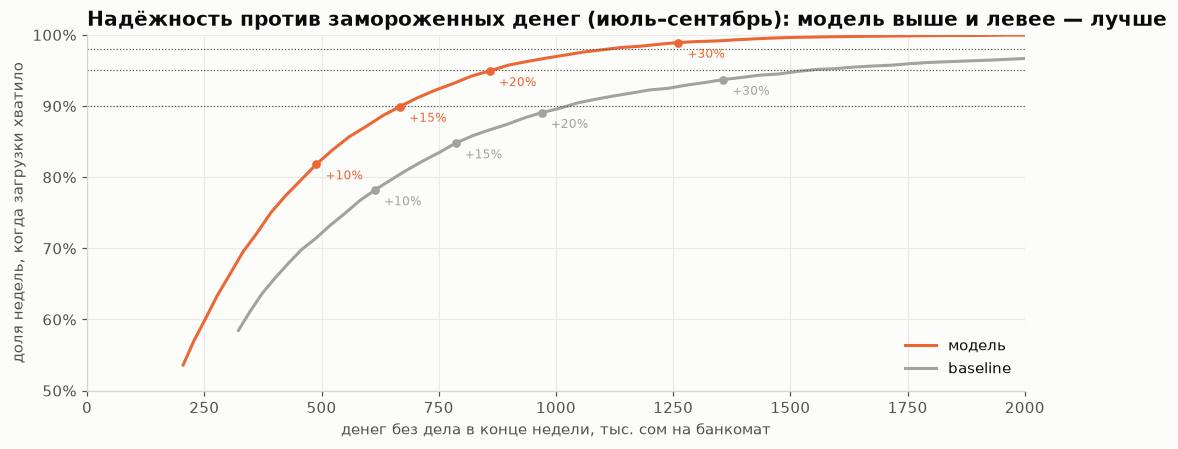

In [10]:
fig, ax = plt.subplots(figsize=(11, 4.2))
for m, c in [("модель", ORANGE), ("baseline", GRAY)]:
    cur = curves[m]
    ax.plot(cur["без дела, сом"] / 1e3, cur["хватило"], color=c, label=f"{m}")
    for b in (0.10, 0.15, 0.20, 0.30):
        r = cur.loc[b]
        ax.scatter(r["без дела, сом"] / 1e3, r["хватило"], color=c, s=22, zorder=3)
        ax.annotate(f"+{b:.0%}", (r["без дела, сом"] / 1e3, r["хватило"]), textcoords="offset points",
                    xytext=(6, -10), fontsize=8, color=c)
for t in TARGETS:
    ax.axhline(t, color=INK2, linestyle=":", linewidth=0.8)
ax.yaxis.set_major_formatter(pct0)
ax.set_ylim(0.5, 1.0); ax.set_xlim(0, 2000)
ax.set_xlabel("денег без дела в конце недели, тыс. сом на банкомат")
ax.set_ylabel("доля недель, когда загрузки хватило")
ax.set_title("Надёжность против замороженных денег (июль–сентябрь): модель выше и левее — лучше")
ax.legend(loc="lower right")
save(fig, "22_buffer_tradeoff"); plt.show()

## 5. Итог

| Вопрос | Ответ |
|---|---|
| Не повезло ли с периодом проверки? | Нет. В каждом квартале 2025 модель лучше baseline на **22–25%** (WAPE 22,6–25,0% против 29,0–32,5%). Чем длиннее история для обучения, тем ниже ошибка. |
| Что даёт модели качество? | **История выдачи** (без неё ошибка +7,4 п.п.) и **календарь**: пенсии, зарплаты, день недели (+5,5 п.п.). Место установки банкомата даёт +1,4 п.п. **Погода и скачки курса не помогают:** без погоды ошибка даже чуть ниже. Модель можно упростить. |
| Почему за неделю ошибка 9,4%, а за день 22,7%? | Ошибки разных дней почти **независимы** (корреляция +0,02), поэтому 59% из них гасят друг друга в недельной сумме. По теории независимые ошибки уменьшаются в √7 ≈ 2,6 раза, это примерно 8,6%: близко к факту. Систематического перекоса почти нет (+0,8%). |
| Какой запас закладывать? | Для **95% недель без опустошения** нужен запас **21%** к прогнозу модели, у baseline 35%. При этом в банкомате остаётся без дела в среднем **0,86 млн** сом вместо 1,43 млн, **≈68 млн сом на сеть из 120 банкоматов**. Запас выбран на июле–сентябре и подтвердился на октябре–декабре (96,8%). Для 98% недель разница ещё больше: модели нужен запас 27%, baseline 62% (без дела 1,09 млн против 2,44 млн сом). |

Главный вывод для банка: ценность модели не только в 23% меньшей дневной ошибке, но и в том, что при той же надёжности в банкоматах можно держать **на 40% меньше лишних наличных**.